<a href="https://colab.research.google.com/github/NethmiAmasha/Deep-Learning-for-Vision/blob/main/EN4554_AS02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#EN4554 Assignment 2 on CNNs
----

Name: Pathirana P.N.A

Index No.: 220449F


### Task 1: Backpropagation

(a) Linear, ReLU, and softmax cross-entropy

In [17]:
import torch

class Linear:
    def __init__(self, in_features, out_features, dtype=torch.float32, generator=None):
        std = (2.0 / in_features) ** 0.5   # Kaiming initialization
        self.W = torch.randn(in_features, out_features, dtype=dtype, generator=generator) * std
        self.b = torch.zeros(out_features, dtype=dtype)
        self.dW = torch.zeros_like(self.W)
        self.db = torch.zeros_like(self.b)

    def forward(self, x):
        self.x = x
        return x @ self.W + self.b

    def backward(self, dout):
        self.dW = self.x.T @ dout
        self.db = dout.sum(dim=0)
        return dout @ self.W.T


class ReLU:
    def forward(self, x):
        self.mask = (x > 0).to(x.dtype)
        return x * self.mask

    def backward(self, dout):
        return dout * self.mask


class SoftmaxCrossEntropy:
    def forward(self, logits, y):
        shifted = logits - logits.max(dim=1, keepdim=True).values    # numerical stability
        log_probs = shifted - torch.logsumexp(shifted, dim=1, keepdim=True)
        self.probs = log_probs.exp()
        self.y = y
        N = logits.shape[0]
        return -log_probs[torch.arange(N), y].mean()

    def backward(self):
        N = self.probs.shape[0]
        dlogits = self.probs.clone()
        dlogits[torch.arange(N), self.y] -= 1.0
        return dlogits / N

MLP

In [18]:
class MLP:
    def __init__(self, dims, dtype=torch.float32, seed=0):
        g = torch.Generator().manual_seed(seed)
        self.layers = []
        for i in range(len(dims) - 1):
            self.layers.append(Linear(dims[i], dims[i + 1], dtype=dtype, generator=g))
            if i < len(dims) - 2:
                self.layers.append(ReLU())
        self.loss_fn = SoftmaxCrossEntropy()

    def forward(self, x):
        for layer in self.layers:
            x = layer.forward(x)
        return x

    def loss(self, x, y):
        return self.loss_fn.forward(self.forward(x), y)

    def backward(self):
        grad = self.loss_fn.backward()
        for layer in reversed(self.layers):
            grad = layer.backward(grad)

    def linear_layers(self):
        return [l for l in self.layers if isinstance(l, Linear)]

(b) Verifying the gradients against autograd and against centred finite differences

In [19]:
import torch
import torch.nn.functional as F

def rel_err(a, b, eps=1e-12):
    return ((a - b).norm() / (a.norm() + b.norm() + eps)).item()

def autograd_reference(model, x, y):
    params = []
    for layer in model.linear_layers():
        W = layer.W.clone().requires_grad_(True)
        b = layer.b.clone().requires_grad_(True)
        params.append((W, b))

    h = x
    for i, (W, b) in enumerate(params):
        h = h @ W + b
        if i < len(params) - 1:
            h = torch.relu(h)
    loss = F.cross_entropy(h, y)    # mean softmax cross-entropy
    loss.backward()
    return loss.item(), [(W.grad, b.grad) for W, b in params]

In [20]:
def finite_diff_check(model, x, y, eps=1e-6, n_samples=25, seed=0):
    g = torch.Generator().manual_seed(seed)
    model.loss(x, y)
    model.backward()   # manual gradients
    results = []
    for li, layer in enumerate(model.linear_layers()):
        for name in ("W", "b"):
            param = getattr(layer, name)
            grad = getattr(layer, "d" + name)
            flat = param.view(-1)
            idx = torch.randperm(flat.numel(), generator=g)[:n_samples]
            ana = grad.reshape(-1)[idx]  # analytic gradient at the sampled entries
            num = torch.empty_like(ana)
            for k, i in enumerate(idx.tolist()):
                orig = flat[i].item()
                flat[i] = orig + eps
                loss_plus = model.loss(x, y).item()
                flat[i] = orig - eps
                loss_minus = model.loss(x, y).item()
                flat[i] = orig
                num[k] = (loss_plus - loss_minus) / (2 * eps)
            results.append((f"layer{li}.{name}",
                            rel_err(ana, num),
                            torch.allclose(ana, num, rtol=1e-5, atol=1e-7)))
    return results

In [23]:
torch.manual_seed(0)
model = MLP([3072, 64, 32, 10], dtype=torch.float64, seed=0)
x = torch.randn(16, 3072, dtype=torch.float64)
y = torch.randint(0, 10, (16,))

# manual vs autograd
loss = model.loss(x, y).item()
model.backward()
ag_loss, ag_grads = autograd_reference(model, x, y)
print(f"loss  manual={loss:.12f}  autograd={ag_loss:.12f}\n")

print("=== Manual vs autograd ===")
for li, (layer, (gW, gb)) in enumerate(zip(model.linear_layers(), ag_grads)):
    for name, mine, ref in (("W", layer.dW, gW), ("b", layer.db, gb)):
        print(f"layer{li}.{name}: rel err = {rel_err(mine, ref):.2e}   "
              f"allclose = {torch.allclose(mine, ref, rtol=1e-7, atol=1e-10)}")

# manual vs finite differences
print("\n=== Manual vs centred finite differences ===")
for name, err, ok in finite_diff_check(model, x, y):
    print(f"{name}: rel err = {err:.2e}   allclose = {ok}")

loss  manual=3.217372143849  autograd=3.217372143849

=== Manual vs autograd ===
layer0.W: rel err = 8.57e-17   allclose = True
layer0.b: rel err = 7.63e-17   allclose = True
layer1.W: rel err = 5.33e-17   allclose = True
layer1.b: rel err = 5.53e-17   allclose = True
layer2.W: rel err = 4.61e-17   allclose = True
layer2.b: rel err = 2.30e-17   allclose = True

=== Manual vs centred finite differences ===
layer0.W: rel err = 2.09e-09   allclose = True
layer0.b: rel err = 1.54e-09   allclose = True
layer1.W: rel err = 1.46e-09   allclose = True
layer1.b: rel err = 1.40e-09   allclose = True
layer2.W: rel err = 8.26e-10   allclose = True
layer2.b: rel err = 6.59e-10   allclose = True


The manual gradients match autograd to ~1e-17 relative error and centred finite differences to ~1e-9, with torch.allclose passing for every parameter. So, the backward pass is correct. The check ran in float64 on a smaller MLP (3072-64-32-10, 16 random inputs), and the finite-difference check tested 25 randomly sampled entries per tensor with ε = 1e-6.

 (c) Training with SGD on flattened CIFAR-10 images

Images are flattened to 3072-d vectors. The manual MLP is trained with plain minibatch SGD.

Hyperparameters: learning rate = 0.05, batch size = 128, 20 epochs, data reshuffled each epoch, seed 0.

In [27]:
!mkdir -p ./data
!cp -r /content/drive/MyDrive/cifar_data/* ./data/

In [28]:
import random
import numpy as np
import torch
import torchvision

SEED = 0
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Load the raw training set (uint8 images, shape (50000, 32, 32, 3))
full_train = torchvision.datasets.CIFAR10(root="./data", train=True, download=True)
X_all = torch.from_numpy(full_train.data).permute(0, 3, 1, 2).float() / 255.0
y_all = torch.tensor(full_train.targets, dtype=torch.long)

# 45k / 5k split with a fixed permutation
perm = torch.randperm(len(X_all), generator=torch.Generator().manual_seed(SEED))
tr_idx, va_idx = perm[:45000], perm[45000:]
train_x, train_y = X_all[tr_idx], y_all[tr_idx]
val_x, val_y = X_all[va_idx], y_all[va_idx]

# Per-channel normalization using training set only
mean = train_x.mean(dim=(0, 2, 3), keepdim=True)
std = train_x.std(dim=(0, 2, 3), keepdim=True)
train_x = (train_x - mean) / std
val_x = (val_x - mean) / std

print(train_x.shape, val_x.shape, train_y.shape, val_y.shape)
print("train mean per channel:", train_x.mean(dim=(0, 2, 3)))
print("train std per channel: ", train_x.std(dim=(0, 2, 3)))

torch.Size([45000, 3, 32, 32]) torch.Size([5000, 3, 32, 32]) torch.Size([45000]) torch.Size([5000])
train mean per channel: tensor([1.8961e-07, 5.6320e-06, 2.1302e-06])
train std per channel:  tensor([1., 1., 1.])


In [29]:
import numpy as np
import matplotlib.pyplot as plt

# Flatten images
Xtr, ytr = train_x.reshape(len(train_x), -1), train_y
Xva, yva = val_x.reshape(len(val_x), -1), val_y
print(Xtr.shape, Xva.shape)

def accuracy(model, X, y, bs=1000):
    correct = 0
    for i in range(0, len(X), bs):
        correct += (model.forward(X[i:i+bs]).argmax(dim=1) == y[i:i+bs]).sum().item()
    return correct / len(X)

def eval_loss(model, X, y, bs=1000):
    total = 0.0
    for i in range(0, len(X), bs):
        xb, yb = X[i:i+bs], y[i:i+bs]
        total += model.loss(xb, yb).item() * len(xb)
    return total / len(X)

def sgd_step(model, lr):
    for layer in model.linear_layers():
        layer.W -= lr * layer.dW
        layer.b -= lr * layer.db

torch.Size([45000, 3072]) torch.Size([5000, 3072])


In [30]:
def train_mlp(dims, lr, epochs, batch_size, seed=0):
    model = MLP(dims, seed=seed)
    g = torch.Generator().manual_seed(seed)
    hist = {"iter_loss": [], "train_loss": [], "val_loss": [], "val_acc": []}
    N = len(Xtr)

    for ep in range(epochs):
        perm = torch.randperm(N, generator=g)
        for i in range(0, N, batch_size):
            idx = perm[i:i + batch_size]
            loss = model.loss(Xtr[idx], ytr[idx])  # forward
            model.backward()  # manual backward
            sgd_step(model, lr)  # parameter update
            hist["iter_loss"].append(loss.item())

        hist["train_loss"].append(eval_loss(model, Xtr, ytr))
        hist["val_loss"].append(eval_loss(model, Xva, yva))
        hist["val_acc"].append(accuracy(model, Xva, yva))
        print(f"epoch {ep+1:2d} | train loss {hist['train_loss'][-1]:.4f} | "
              f"val loss {hist['val_loss'][-1]:.4f} | val acc {hist['val_acc'][-1]:.4f}")
    return model, hist

mlp, hist = train_mlp([3072, 512, 256, 10], lr=0.05, epochs=20, batch_size=128)

epoch  1 | train loss 1.4337 | val loss 1.5851 | val acc 0.4410
epoch  2 | train loss 1.2957 | val loss 1.5312 | val acc 0.4706
epoch  3 | train loss 1.2256 | val loss 1.5402 | val acc 0.4698
epoch  4 | train loss 1.0560 | val loss 1.4680 | val acc 0.5002
epoch  5 | train loss 0.9900 | val loss 1.4727 | val acc 0.4978
epoch  6 | train loss 0.9105 | val loss 1.4869 | val acc 0.5090
epoch  7 | train loss 0.8201 | val loss 1.4991 | val acc 0.5064
epoch  8 | train loss 0.8055 | val loss 1.5666 | val acc 0.4970
epoch  9 | train loss 0.6829 | val loss 1.5518 | val acc 0.5026
epoch 10 | train loss 0.7120 | val loss 1.6819 | val acc 0.4866
epoch 11 | train loss 0.6372 | val loss 1.6961 | val acc 0.4878
epoch 12 | train loss 0.6477 | val loss 1.8777 | val acc 0.4892
epoch 13 | train loss 0.5057 | val loss 1.8010 | val acc 0.4970
epoch 14 | train loss 0.5514 | val loss 1.9347 | val acc 0.4716
epoch 15 | train loss 0.4172 | val loss 1.8856 | val acc 0.4892
epoch 16 | train loss 0.3675 | val loss 

Plotting the loss and report validation accuracy.

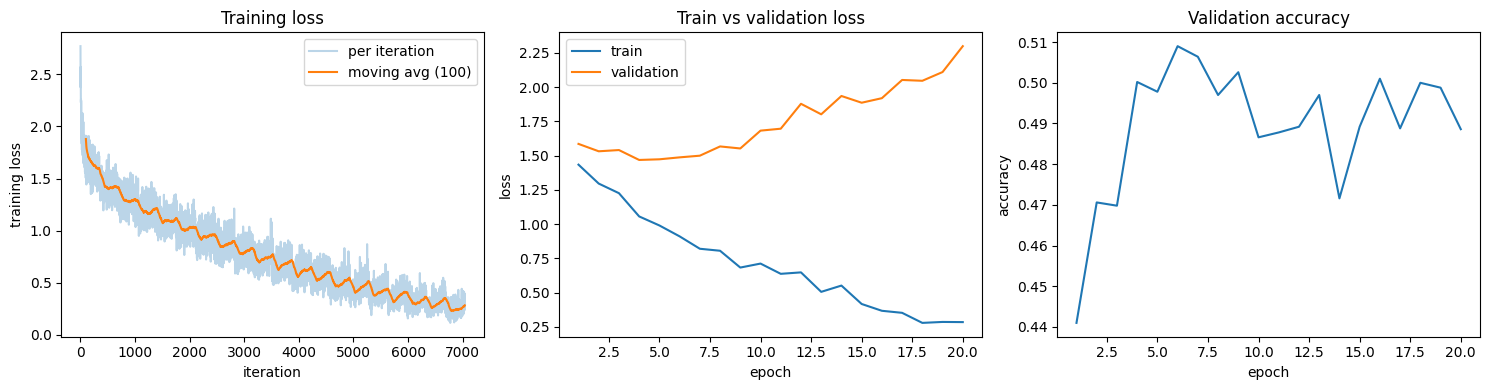

Final validation accuracy: 0.4886
Best validation accuracy:  0.5090 (epoch 6)


In [31]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

# Training loss per iteration
it = np.array(hist["iter_loss"])
k = 100
ax[0].plot(it, alpha=0.3, label="per iteration")
ax[0].plot(np.arange(k - 1, len(it)), np.convolve(it, np.ones(k) / k, mode="valid"),
           label=f"moving avg ({k})")
ax[0].set(xlabel="iteration", ylabel="training loss", title="Training loss")
ax[0].legend()

# Epoch-level train vs validation loss
ep = np.arange(1, len(hist["train_loss"]) + 1)
ax[1].plot(ep, hist["train_loss"], label="train")
ax[1].plot(ep, hist["val_loss"], label="validation")
ax[1].set(xlabel="epoch", ylabel="loss", title="Train vs validation loss")
ax[1].legend()

# Validation accuracy
ax[2].plot(ep, hist["val_acc"])
ax[2].set(xlabel="epoch", ylabel="accuracy", title="Validation accuracy")

plt.tight_layout()
plt.show()

print(f"Final validation accuracy: {hist['val_acc'][-1]:.4f}")
print(f"Best validation accuracy:  {max(hist['val_acc']):.4f} (epoch {int(np.argmax(hist['val_acc'])) + 1})")

The MLP reaches a final validation accuracy of 48.4% (best 51.3% at epoch 18), against 10% for random guessing. Training loss falls from 1.43 after epoch 1 to 0.29 after epoch 20.

The per-iteration loss is noisy because each step uses a 128-image minibatch, while the moving average shows a steady decline. Validation loss is lowest at epoch 5 (1.48) and then rises to 2.37 while training loss keeps decreasing. This shows that the network overfits from about epoch 5 onward. An MLP on flattened pixels ignores spatial structure and has no translation invariance. This limits its accuracy.

(d) Plotting the per-layer gradient norm at initialization with sigmoid and with ReLU for a 10-layer MLP

A 10-layer MLP is built with sigmoid and with ReLU activations. Both use the same seed. Therefore they have identical Kaiming-initialized weights and only the activation differs. At initialization, one forward/backward pass is run on 256 training images and the Frobenius norm of `dW` for each linear layer is recorded. The results are averaged over 5 seeds.

In [32]:
class Sigmoid:
    def forward(self, x):
        self.out = 1.0 / (1.0 + torch.exp(-x))
        return self.out

    def backward(self, dout):
        return dout * self.out * (1.0 - self.out)

def make_mlp(dims, act, seed=0):
    model = MLP(dims, seed=seed)
    if act == "sigmoid":
        model.layers = [Sigmoid() if isinstance(l, ReLU) else l for l in model.layers]
    return model

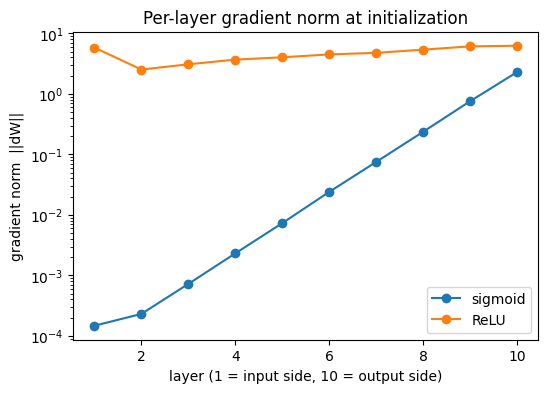

sigmoid  layer1 = 1.47e-04, layer10 = 2.30e+00, ratio layer10/layer1 = 1.6e+04
relu     layer1 = 5.82e+00, layer10 = 6.25e+00, ratio layer10/layer1 = 1.1e+00


In [33]:
dims = [3072] + [256] * 9 + [10]
xb, yb = Xtr[:256], ytr[:256]

def layer_grad_norms(model, x, y):
    model.loss(x, y)
    model.backward()
    return [l.dW.norm().item() for l in model.linear_layers()]

seeds = range(5)
norms = {act: np.array([layer_grad_norms(make_mlp(dims, act, seed=s), xb, yb) for s in seeds])
         for act in ("sigmoid", "relu")}

layers = np.arange(1, 11)
plt.figure(figsize=(6, 4))
for act, label in (("sigmoid", "sigmoid"), ("relu", "ReLU")):
    plt.plot(layers, norms[act].mean(axis=0), marker="o", label=label)
plt.yscale("log")
plt.xlabel("layer (1 = input side, 10 = output side)")
plt.ylabel("gradient norm  ||dW||")
plt.title("Per-layer gradient norm at initialization")
plt.legend()
plt.show()

for act in norms:
    m = norms[act].mean(axis=0)
    print(f"{act:8s} layer1 = {m[0]:.2e}, layer10 = {m[-1]:.2e}, ratio layer10/layer1 = {m[-1]/m[0]:.1e}")

When using sigmoid, the gradient norm drops steadily towards the input. Layer 1 has norm 1.47e-4 and 2.3 at layer 10 which gives a ratio of about 1.6e4. When using ReLU, the norm for layer 1 is 5.82 and norm for layer 10 is 6.25 which gives a ratio of only 1.1.

Backpropagation multiplies the gradient by the activation derivative at every layer. The sigmoid derivative is at most 0.25, and smaller when units saturate, so the gradient shrinks by a roughly constant factor per layer and decays exponentially with depth. The early layers get almost no learning signal, and with the same learning rate they learn far more slowly than the layers near the output. The ReLU derivative is exactly 1 for active units, so the gradient passes through without shrinkage, and Kaiming initialization keeps the signal variance stable from layer to layer. Both networks use the same Kaiming-initialized weights, so the difference comes from the activation function. This is why ReLU networks can be trained at depths where sigmoid networks cannot.

### Task 2: Optimizers

(a) SGD with momentum and Adam

- SGD with momentum: `buf ← μ·buf + g`, `p ← p − lr·buf`. With `μ = 0` it reduces to plain SGD.
- Adam: `m ← β₁m + (1−β₁)g`, `v ← β₂v + (1−β₂)g²`, `m̂ = m/(1−β₁ᵗ)`, `v̂ = v/(1−β₂ᵗ)`, `p ← p − lr·m̂/(√v̂ + ε)`.

In [34]:
import torch
import torch.nn.functional as F
from torch.optim import Optimizer

class SGDMomentum(Optimizer):
    def __init__(self, params, lr=0.01, momentum=0.9):
        super().__init__(params, dict(lr=lr, momentum=momentum))

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            for p in group["params"]:
                if p.grad is None:
                    continue
                state = self.state[p]
                if "buf" not in state:
                    state["buf"] = p.grad.clone() # first step: buf = g
                else:
                    state["buf"].mul_(group["momentum"]).add_(p.grad)
                p.add_(state["buf"], alpha=-group["lr"])
        return loss


class Adam(Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps))

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            b1, b2 = group["betas"]
            for p in group["params"]:
                if p.grad is None:
                    continue
                g, state = p.grad, self.state[p]
                if not state:
                    state["t"] = 0
                    state["m"] = torch.zeros_like(p)
                    state["v"] = torch.zeros_like(p)
                state["t"] += 1
                t, m, v = state["t"], state["m"], state["v"]
                m.mul_(b1).add_(g, alpha=1 - b1)
                v.mul_(b2).addcmul_(g, g, value=1 - b2)
                m_hat = m / (1 - b1 ** t)  # bias correction
                v_hat = v / (1 - b2 ** t)
                p.addcdiv_(m_hat, v_hat.sqrt().add_(group["eps"]), value=-group["lr"])
        return loss

Comparison with `torch.optim`

In [35]:
def run(opt_cls, steps=100, **kw):
    torch.manual_seed(0)
    net = torch.nn.Sequential(torch.nn.Linear(20, 16), torch.nn.ReLU(),
                              torch.nn.Linear(16, 5)).double()
    opt = opt_cls(net.parameters(), **kw)
    g = torch.Generator().manual_seed(1)
    X = torch.randn(64, 20, generator=g, dtype=torch.float64)
    y = torch.randint(0, 5, (64,), generator=g)
    for _ in range(steps):
        opt.zero_grad()
        F.cross_entropy(net(X), y).backward()
        opt.step()
    return torch.cat([p.detach().flatten() for p in net.parameters()])

checks = [("SGD (momentum=0)", SGDMomentum, torch.optim.SGD, dict(lr=0.05, momentum=0.0)),
          ("SGD + momentum",   SGDMomentum, torch.optim.SGD, dict(lr=0.05, momentum=0.9)),
          ("Adam",             Adam,        torch.optim.Adam, dict(lr=1e-2))]

for name, mine, ref, kw in checks:
    a, b = run(mine, **kw), run(ref, **kw)
    print(f"{name:17s} max |diff| = {(a - b).abs().max().item():.2e}   "
          f"allclose = {torch.allclose(a, b, rtol=1e-9, atol=1e-12)}")

SGD (momentum=0)  max |diff| = 0.00e+00   allclose = True
SGD + momentum    max |diff| = 0.00e+00   allclose = True
Adam              max |diff| = 5.55e-16   allclose = True


Both custom optimizers match their `torch.optim` counterparts. After 100 steps the maximum parameter difference is 0 for SGD, with and without momentum and 5.55e-16 for Adam, and `torch.allclose` passes in all three cases. The SGD results are bit-identical because the update uses the same operations in the same order as PyTorch's. The tiny Adam difference is floating-point rounding only.

(b) Plotting the trajectories of SGD, SGD with momentum, and Adam

`f(x, y) = ½(x² + 50y²)` has gradient `(x, 50y)`. So, it is 50 times steeper in `y` than in `x`. I take starting point as (10, 1), and run 150 steps of:
- SGD with a learning rate 0.03
- SGD with momentum with a learning rate of 0.03 and momentum of 0.9
- Adam with a learning rate of 0.3

In [36]:
import numpy as np
import matplotlib.pyplot as plt

def f(p):
    return 0.5 * (p[0] ** 2 + 50 * p[1] ** 2)

def trajectory(opt_cls, steps=150, **kw):
    p = torch.tensor([10.0, 1.0], requires_grad=True)
    opt = opt_cls([p], **kw)
    path = [p.detach().numpy().copy()]
    for _ in range(steps):
        opt.zero_grad()
        f(p).backward()
        opt.step()
        path.append(p.detach().numpy().copy())
    return np.array(path)

paths = {
    "SGD (lr 0.03)": trajectory(SGDMomentum, lr=0.03, momentum=0.0),
    "SGD + momentum (lr 0.03, μ 0.9)": trajectory(SGDMomentum, lr=0.03, momentum=0.9),
    "Adam (lr 0.3)": trajectory(Adam, lr=0.3),
}

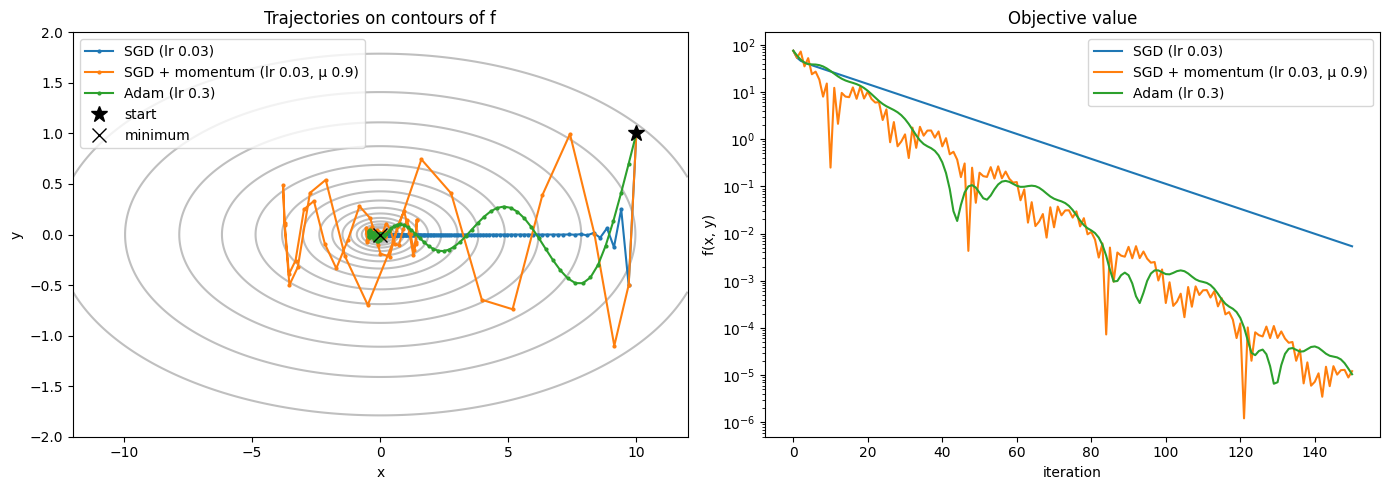

SGD (lr 0.03)                      final (x, y) = (+1.04e-01, +0.00e+00),  f = 5.38e-03
SGD + momentum (lr 0.03, μ 0.9)    final (x, y) = (+3.74e-03, -4.54e-04),  f = 1.21e-05
Adam (lr 0.3)                      final (x, y) = (-4.55e-03, +6.23e-05),  f = 1.04e-05


In [37]:
# plots
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# contours and trajectories
xs, ys = np.linspace(-12, 12, 400), np.linspace(-2, 2, 400)
X, Y = np.meshgrid(xs, ys)
Z = 0.5 * (X ** 2 + 50 * Y ** 2)
ax[0].contour(X, Y, Z, levels=np.geomspace(0.1, 80, 15), colors="gray", alpha=0.5)
for name, path in paths.items():
    ax[0].plot(path[:, 0], path[:, 1], marker=".", markersize=4, label=name)
ax[0].plot(*paths["Adam (lr 0.3)"][0], "k*", markersize=12, label="start")
ax[0].plot(0, 0, "kx", markersize=10, label="minimum")
ax[0].set(xlabel="x", ylabel="y", title="Trajectories on contours of f")
ax[0].legend()

# f vs iteration
for name, path in paths.items():
    ax[1].plot(0.5 * (path[:, 0] ** 2 + 50 * path[:, 1] ** 2), label=name)
ax[1].set(yscale="log", xlabel="iteration", ylabel="f(x, y)", title="Objective value")
ax[1].legend()

plt.tight_layout()
plt.show()

for name, path in paths.items():
    print(f"{name:34s} final (x, y) = ({path[-1,0]:+.2e}, {path[-1,1]:+.2e}),  f = {0.5*(path[-1,0]**2 + 50*path[-1,1]**2):.2e}")

The left plot shows the trajectories of the three optimizers over the contours of `f`. Plain SGD drops to `y ≈ 0` within a few steps and then goes along the flat `x` axis. SGD with momentum takes a zigzag like path with large swings in `y` and `x`, but it gets close to the minimum. Adam takes a smooth, curved path.

The right plot shows `f` against iteration on a log scale. Here, SGD decreases as a straight line, and with momentum it decreases fastest but very noisily, and Adam decreases almost as fast with oscillations of much smaller amplitude.

According to the plots, the step size of plain SGD is limited by the steep direction and the `y` coordinate converges faster than `x`. After 150 steps `x` is still 0.104 eventhough `y` became 0 and `f = 5.38e-03`. SGD with momentum accumulates gradient along the `x` direction, which speeds up progress in that direction with an effective step size. But, it has a zig-zag path. Its final `f = 1.21e-05` is much lower than SGD's. In Adam both directions move at a similar speed, and its path shows a less zigzag behaviour than that of SGD with momentum. Its final `f = 1.04e-05` is much lower than SGD's.

This shows that for an ill-conditioned problem plain SGD is slow because one learning rate is not suitable, whereas momentum and Adam both fix this issue.

(c) Training a small CNN with three optimizers at three learning rates

- A small CNN with 3 convolution blocks (with conv3×3, ReLU, maxpool each) with 32/64/128 channels, then a linear classifier
- ~290k parameters, no batch norm
- Trained for 10 epochs with batch size 128 and seed 0
- Trained using plain SGD, SGD with momentum (μ = 0.9) and Adam, each at three learning rates. Their learning rates differ as their useful ranges differ.
- SGD is trained for the learning rates 0.003, 0.01 and 0.03.
- SGD with momentum is trained for the learning rates 0.001, 0.003 and 0.01.
- Adam is trained for the learning rates 1e-4, 1e-3 and 1e-2

In [38]:
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

Xtr_g, ytr_g = train_x.to(device), train_y.to(device)
Xva_g, yva_g = val_x.to(device), val_y.to(device)

def make_cnn():
    def block(i, o):
        return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2))
    return nn.Sequential(block(3, 32), block(32, 64), block(64, 128),
                         nn.Flatten(), nn.Linear(128 * 4 * 4, 10))

@torch.no_grad()
def evaluate(model, X, y, bs=1000):
    model.eval()
    loss, correct = 0.0, 0
    for i in range(0, len(X), bs):
        out = model(X[i:i + bs])
        loss += F.cross_entropy(out, y[i:i + bs], reduction="sum").item()
        correct += (out.argmax(1) == y[i:i + bs]).sum().item()
    return loss / len(X), correct / len(X)

def train_cnn(opt_cls, lr, epochs=10, batch_size=128, seed=0, **kw):
    torch.manual_seed(seed)
    model = make_cnn().to(device)
    opt = opt_cls(model.parameters(), lr=lr, **kw)
    g = torch.Generator(device=device).manual_seed(seed)
    hist = {"train_loss": [], "val_loss": [], "val_acc": []}
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(Xtr_g), device=device, generator=g)
        running = 0.0
        for i in range(0, len(perm), batch_size):
            idx = perm[i:i + batch_size]
            opt.zero_grad()
            loss = F.cross_entropy(model(Xtr_g[idx]), ytr_g[idx])
            loss.backward()
            opt.step()
            running += loss.item() * len(idx)
        vl, va = evaluate(model, Xva_g, yva_g)
        hist["train_loss"].append(running / len(perm))
        hist["val_loss"].append(vl)
        hist["val_acc"].append(va)
    return hist

print("parameters:", sum(p.numel() for p in make_cnn().parameters()))

device: cuda
parameters: 113738


In [39]:
grid = {
    "SGD": (SGDMomentum, dict(momentum=0.0), [0.003, 0.01, 0.03]),
    "SGD+momentum": (SGDMomentum, dict(momentum=0.9), [0.001, 0.003, 0.01]),
    "Adam": (Adam,        dict(),             [1e-4, 1e-3, 1e-2]),
}

results = {}
for name, (cls, kw, lrs) in grid.items():
    for lr in lrs:
        h = train_cnn(cls, lr, **kw)
        results[(name, lr)] = h
        print(f"{name:13s} lr={lr:<7g} final val acc = {h['val_acc'][-1]:.4f}   "
              f"final train loss = {h['train_loss'][-1]:.4f}")

SGD           lr=0.003   final val acc = 0.4558   final train loss = 1.4840
SGD           lr=0.01    final val acc = 0.5710   final train loss = 1.1219
SGD           lr=0.03    final val acc = 0.6964   final train loss = 0.7936
SGD+momentum  lr=0.001   final val acc = 0.6034   final train loss = 1.0957
SGD+momentum  lr=0.003   final val acc = 0.6982   final train loss = 0.7559
SGD+momentum  lr=0.01    final val acc = 0.7358   final train loss = 0.4482
Adam          lr=0.0001  final val acc = 0.6294   final train loss = 1.0313
Adam          lr=0.001   final val acc = 0.7330   final train loss = 0.3972
Adam          lr=0.01    final val acc = 0.5504   final train loss = 1.2173


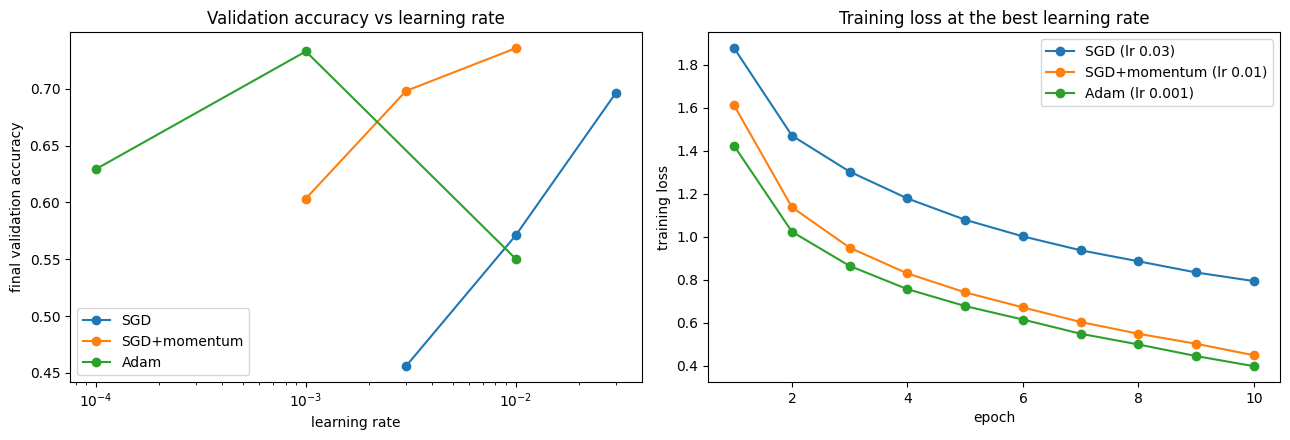

Best learning rates: {'SGD': 0.03, 'SGD+momentum': 0.01, 'Adam': 0.001}
Best validation accuracy: {'SGD': 0.6964, 'SGD+momentum': 0.7358, 'Adam': 0.733}


In [40]:
# Plotting
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

# validation accuracy vs learning rate
for name, (_, _, lrs) in grid.items():
    ax[0].plot(lrs, [results[(name, lr)]["val_acc"][-1] for lr in lrs], marker="o", label=name)
ax[0].set(xscale="log", xlabel="learning rate", ylabel="final validation accuracy",
          title="Validation accuracy vs learning rate")
ax[0].legend()

# training loss at best rate
best = {}
for name, (_, _, lrs) in grid.items():
    best[name] = max(lrs, key=lambda lr: results[(name, lr)]["val_acc"][-1])
    h = results[(name, best[name])]
    ax[1].plot(range(1, len(h["train_loss"]) + 1), h["train_loss"], marker="o",
               label=f"{name} (lr {best[name]:g})")
ax[1].set(xlabel="epoch", ylabel="training loss", title="Training loss at the best learning rate")
ax[1].legend()

plt.tight_layout()
plt.show()

print("Best learning rates:", best)
print("Best validation accuracy:",
      {n: round(results[(n, best[n])]["val_acc"][-1], 4) for n in best})

Best final validation accuracy per optimizer is, SGD 69.6% (lr 0.03), SGD with momentum 73.6% (lr 0.01), Adam 73.3% (lr 0.001). The left plot shows validation accuracy against learning rate on a log axis, and the right plot shows the training loss at each optimizer's best rate. SGD with momentum and Adam give almost same accuracy and both are relatively better than plain SGD.

**Sensitivity**
- **SGD** is very sensitive and, within the tested learning rates, it is still improving at the largest rate. Its accuracy rises from 45.6% (lr 0.003) to 57.1% (0.01) to 69.6% (0.03). The best rate is given at the highest learning rate.
- **SGD with momentum** shows the same pattern: 60.3%, 69.8%, 73.6% for lr 0.001, 0.003, 0.01. Its best rate is also at the highest learning rate.
- **Adam** behaves differently giving 62.9% at 1e-4, 73.3% at 1e-3, and 55.0% at 1e-2. A too small rate undertrains it and a too large rate makes it unstable.

At the best rates, Adam's loss falls fastest, then momentum, then SGD. The ordering of training loss matches the ordering of validation accuracy, so the faster optimizers are also generalizing better rather than overfitting within 10 epochs.